<a href="https://colab.research.google.com/github/allmargo/PortfolioProjects/blob/main/MovieCorrelation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

https://www.kaggle.com/danielgrijalvas/movies


https://drive.google.com/file/d/1eYd69l4otQPKbRf2IIOVWVqG5Gj5Y8_b/view?usp=sharing

In [ ]:
! gdown --id 1eYd69l4otQPKbRf2IIOVWVqG5Gj5Y8_b

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1eYd69l4otQPKbRf2IIOVWVqG5Gj5Y8_b
To: /content/movies.zip
100% 434k/434k [00:00<00:00, 40.4MB/s]


In [ ]:
! unzip /content/movies.zip

Archive:  /content/movies.zip
  inflating: movies.csv              


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns

import matplotlib.pyplot as plt
import matplotlib.mlab as mlab
import matplotlib
plt.style.use('ggplot')
from matplotlib.pyplot import figure

%matplotlib inline
matplotlib.rcParams['figure.figsize'] = (12,8)

pd.options.mode.chained_assignment = None

In [ ]:
df = pd.read_csv('/content/movies.csv')

In [ ]:
df.head()

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000.0,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000.0,46998772.0,Warner Bros.,146.0
1,The Blue Lagoon,R,Adventure,1980,"July 2, 1980 (United States)",5.8,65000.0,Randal Kleiser,Henry De Vere Stacpoole,Brooke Shields,United States,4500000.0,58853106.0,Columbia Pictures,104.0
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,1980,"June 20, 1980 (United States)",8.7,1200000.0,Irvin Kershner,Leigh Brackett,Mark Hamill,United States,18000000.0,538375067.0,Lucasfilm,124.0
3,Airplane!,PG,Comedy,1980,"July 2, 1980 (United States)",7.7,221000.0,Jim Abrahams,Jim Abrahams,Robert Hays,United States,3500000.0,83453539.0,Paramount Pictures,88.0
4,Caddyshack,R,Comedy,1980,"July 25, 1980 (United States)",7.3,108000.0,Harold Ramis,Brian Doyle-Murray,Chevy Chase,United States,6000000.0,39846344.0,Orion Pictures,98.0


In [ ]:
# проверим есть ли в датафрейме пропущенные данные и сколько их

for col in df.columns:
    pct_missing = np.mean(df[col].isnull())
    print('{} - {}%'.format(col, round(pct_missing*100)))

name - 0%
rating - 1%
genre - 0%
year - 0%
released - 0%
score - 0%
votes - 0%
director - 0%
writer - 0%
star - 0%
country - 0%
budget - 28%
gross - 2%
company - 0%
runtime - 0%


In [ ]:
# проверим типы данных столбцов

print(df.dtypes)

name         object
rating       object
genre        object
year          int64
released     object
score       float64
votes       float64
director     object
writer       object
star         object
country      object
budget      float64
gross       float64
company      object
runtime     float64
dtype: object


<Axes: >

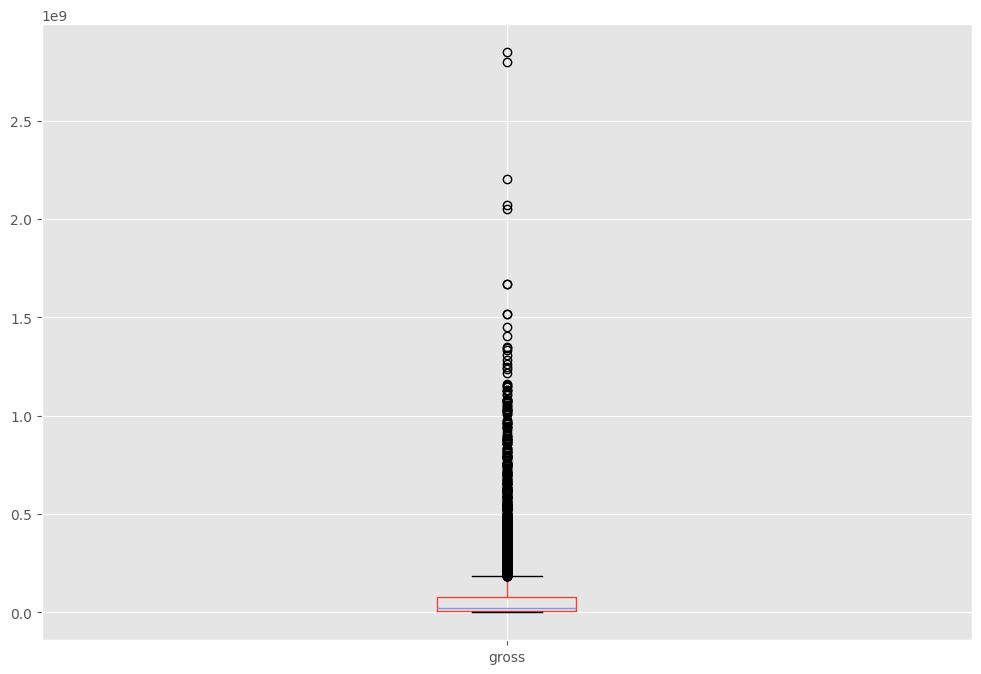

In [ ]:
# проверим выбросы

df.boxplot(column=['gross'])

# Распределение кассовых сборов (gross) крайне неоднородно и имеет сильный правосторонний сдвиг
# Данные не подчиняются нормальному закону

In [ ]:
df.drop_duplicates().tail()

# кол-во строк не изменилось - дубликатов нет

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
7663,More to Life,NaN,Drama,2020,"October 23, 2020 (United States)",3.1,18.0,Joseph Ebanks,Joseph Ebanks,Shannon Bond,United States,7000.0,NaN,NaN,90.0
7664,Dream Round,NaN,Comedy,2020,"February 7, 2020 (United States)",4.7,36.0,Dusty Dukatz,Lisa Huston,Michael Saquella,United States,NaN,NaN,Cactus Blue Entertainment,90.0
7665,Saving Mbango,NaN,Drama,2020,"April 27, 2020 (Cameroon)",5.7,29.0,Nkanya Nkwai,Lynno Lovert,Onyama Laura,United States,58750.0,NaN,Embi Productions,NaN
7666,It's Just Us,NaN,Drama,2020,"October 1, 2020 (United States)",NaN,NaN,James Randall,James Randall,Christina Roz,United States,15000.0,NaN,NaN,120.0
7667,Tee em el,NaN,Horror,2020,"August 19, 2020 (United States)",5.7,7.0,Pereko Mosia,Pereko Mosia,Siyabonga Mabaso,South Africa,NaN,NaN,PK 65 Films,102.0


In [ ]:
# отсортируем данные

df.sort_values(by=['gross'], inplace=False, ascending=False)

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
5445,Avatar,PG-13,Action,2009,"December 18, 2009 (United States)",7.8,1100000.0,James Cameron,James Cameron,Sam Worthington,United States,237000000.0,2.847246e+09,Twentieth Century Fox,162.0
7445,Avengers: Endgame,PG-13,Action,2019,"April 26, 2019 (United States)",8.4,903000.0,Anthony Russo,Christopher Markus,Robert Downey Jr.,United States,356000000.0,2.797501e+09,Marvel Studios,181.0
3045,Titanic,PG-13,Drama,1997,"December 19, 1997 (United States)",7.8,1100000.0,James Cameron,James Cameron,Leonardo DiCaprio,United States,200000000.0,2.201647e+09,Twentieth Century Fox,194.0
6663,Star Wars: Episode VII - The Force Awakens,PG-13,Action,2015,"December 18, 2015 (United States)",7.8,876000.0,J.J. Abrams,Lawrence Kasdan,Daisy Ridley,United States,245000000.0,2.069522e+09,Lucasfilm,138.0
7244,Avengers: Infinity War,PG-13,Action,2018,"April 27, 2018 (United States)",8.4,897000.0,Anthony Russo,Christopher Markus,Robert Downey Jr.,United States,321000000.0,2.048360e+09,Marvel Studios,149.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7663,More to Life,NaN,Drama,2020,"October 23, 2020 (United States)",3.1,18.0,Joseph Ebanks,Joseph Ebanks,Shannon Bond,United States,7000.0,NaN,NaN,90.0
7664,Dream Round,NaN,Comedy,2020,"February 7, 2020 (United States)",4.7,36.0,Dusty Dukatz,Lisa Huston,Michael Saquella,United States,NaN,NaN,Cactus Blue Entertainment,90.0
7665,Saving Mbango,NaN,Drama,2020,"April 27, 2020 (Cameroon)",5.7,29.0,Nkanya Nkwai,Lynno Lovert,Onyama Laura,United States,58750.0,NaN,Embi Productions,NaN
7666,It's Just Us,NaN,Drama,2020,"October 1, 2020 (United States)",NaN,NaN,James Randall,James Randall,Christina Roz,United States,15000.0,NaN,NaN,120.0


<Axes: xlabel='gross', ylabel='budget'>

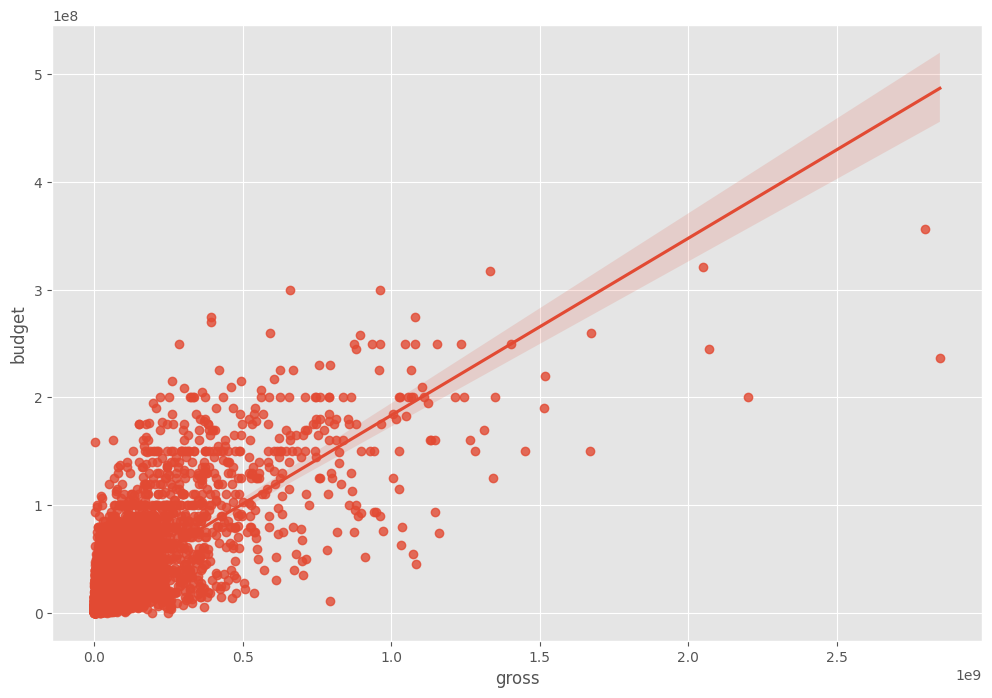

In [ ]:
sns.regplot(x="gross", y="budget", data=df)

<Axes: >

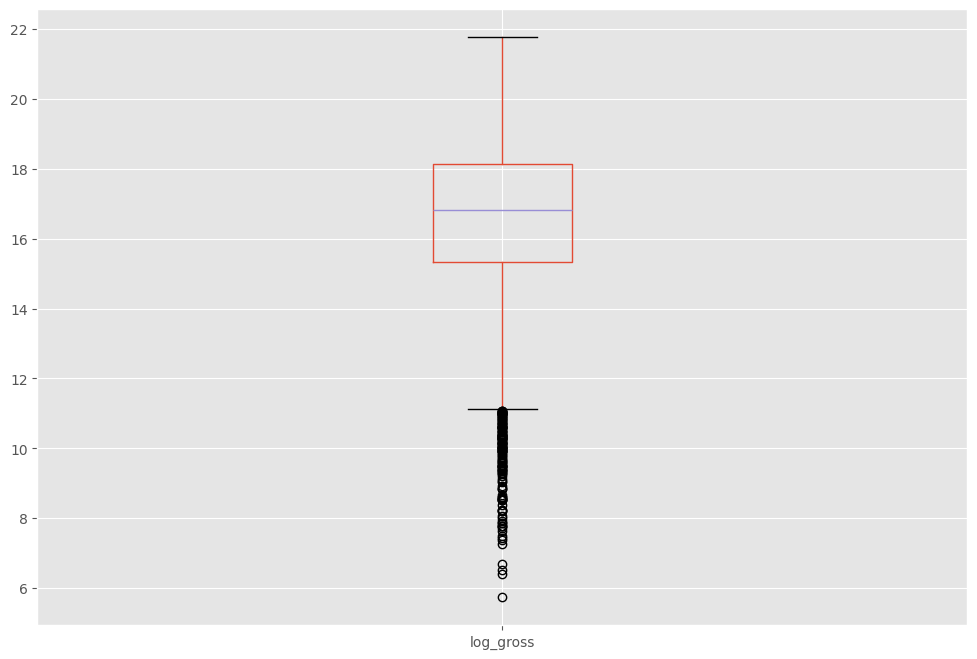

In [ ]:
# исходя из обоих графиков делаем вывод, что нужно логарифмировать данные, потому что в данном виде они нечитаемы

df['log_gross'] = np.log1p(df['gross'])
df['log_budget'] = np.log1p(df['budget'])

df.boxplot(column=['log_gross'])

# данные внутри коробки распределены равномерно. Левосторонний сдвиг - большое кол-во коммерчески неудачных фильмов

<Axes: xlabel='log_gross', ylabel='log_budget'>

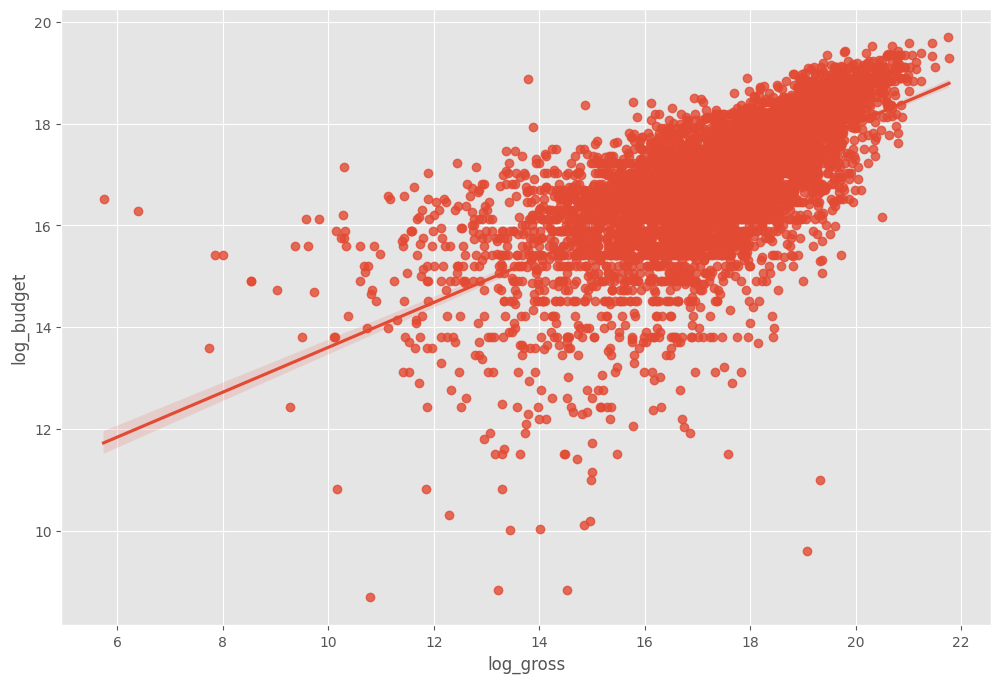

In [ ]:
sns.regplot(x="log_gross", y="log_budget", data=df)

# между бюджетом и сборами явная линейная связь.
# выбросы: точки в правом нижнем углу - фильмы с низким бюджетом, но большими сборами;
# в левом верхнем углу - большой бюджет, низкие сборы.

<Axes: xlabel='score', ylabel='gross'>

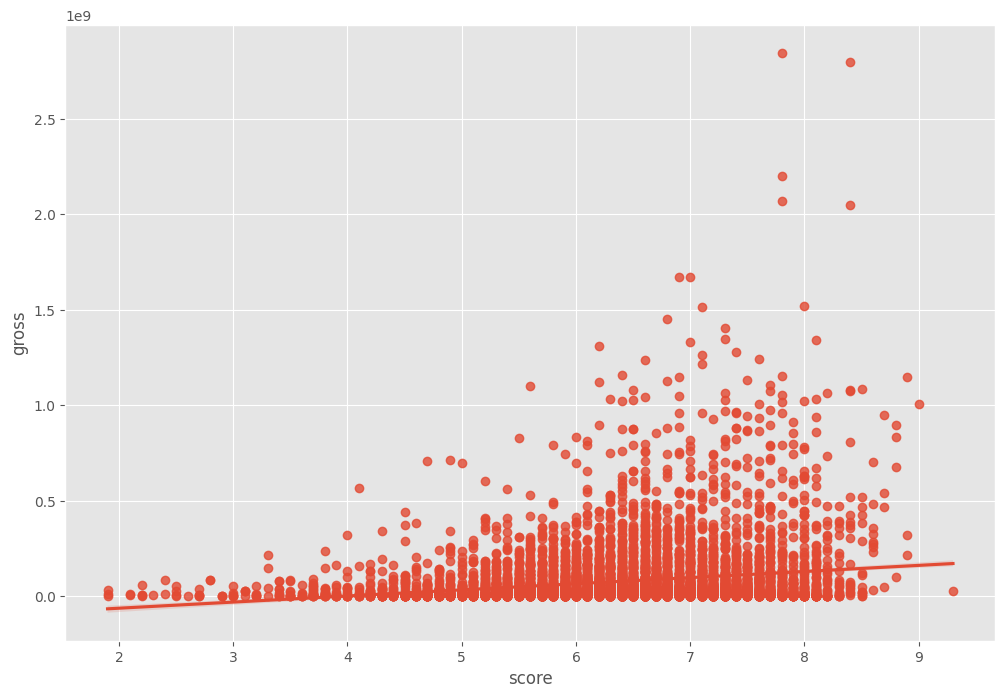

In [ ]:
sns.regplot(x="score", y="gross", data=df)

<Axes: xlabel='score', ylabel='log_gross'>

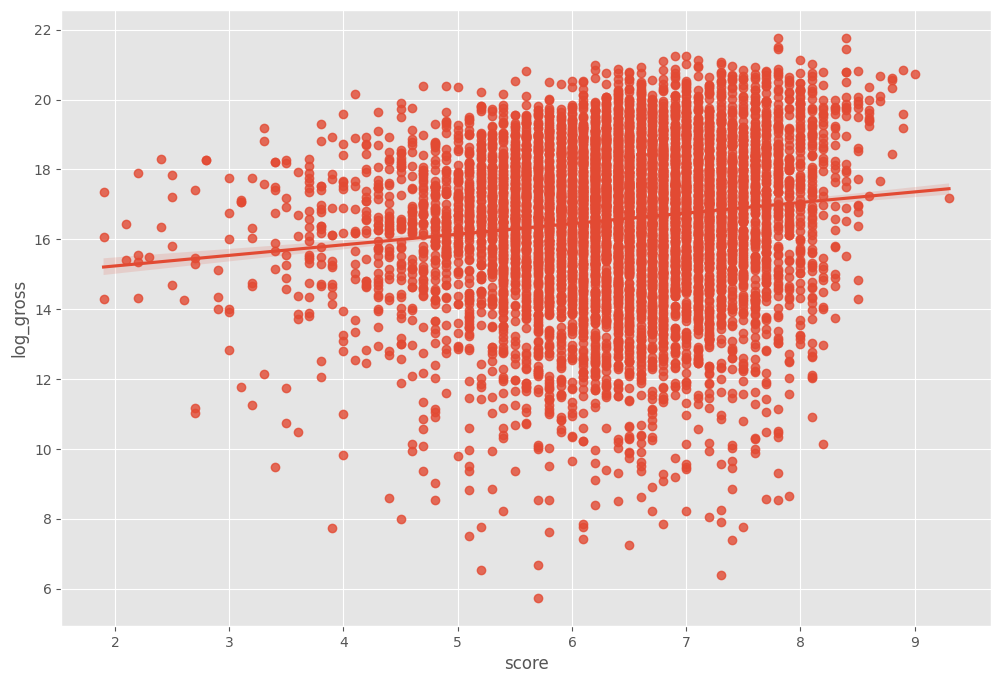

In [ ]:
sns.regplot(x="score", y="log_gross", data=df)

# оценка фильма это плохой предиктор кассовых сборов

In [ ]:
df.corr(method='pearson', numeric_only=True)

,year,score,votes,budget,gross,runtime,log_gross,log_budget
year,1.000000,0.097995,0.222945,0.329321,0.257486,0.120811,0.247163,0.285996
score,0.097995,1.000000,0.409182,0.076254,0.186258,0.399451,0.131832,0.019406
votes,0.222945,0.409182,1.000000,0.442429,0.630757,0.309212,0.479554,0.329306
budget,0.329321,0.076254,0.442429,1.000000,0.740395,0.320447,0.594433,0.740672
gross,0.257486,0.186258,0.630757,0.740395,1.000000,0.245216,0.580479,0.499552
runtime,0.120811,0.399451,0.309212,0.320447,0.245216,1.000000,0.221093,0.337066
log_gross,0.247163,0.131832,0.479554,0.594433,0.580479,0.221093,1.000000,0.655071
log_budget,0.285996,0.019406,0.329306,0.740672,0.499552,0.337066,0.655071,1.000000


In [ ]:
df.corr(method='kendall', numeric_only=True)

,year,score,votes,budget,gross,runtime,log_gross,log_budget
year,1.000000,0.067652,0.331465,0.224120,0.200618,0.097184,0.200618,0.224120
score,0.067652,1.000000,0.300115,-0.000566,0.086046,0.283611,0.086046,-0.000566
votes,0.331465,0.300115,1.000000,0.353702,0.548899,0.198240,0.548899,0.353702
budget,0.224120,-0.000566,0.353702,1.000000,0.512637,0.235483,0.512637,1.000000
gross,0.200618,0.086046,0.548899,0.512637,1.000000,0.168933,1.000000,0.512637
runtime,0.097184,0.283611,0.198240,0.235483,0.168933,1.000000,0.168933,0.235483
log_gross,0.200618,0.086046,0.548899,0.512637,1.000000,0.168933,1.000000,0.512637
log_budget,0.224120,-0.000566,0.353702,1.000000,0.512637,0.235483,0.512637,1.000000


In [ ]:
df.corr(method='spearman', numeric_only=True)

,year,score,votes,budget,gross,runtime,log_gross,log_budget
year,1.000000,0.099045,0.469829,0.317336,0.293084,0.142977,0.293084,0.317336
score,0.099045,1.000000,0.428138,-0.001403,0.126116,0.399857,0.126116,-0.001403
votes,0.469829,0.428138,1.000000,0.502466,0.742050,0.290159,0.742050,0.502466
budget,0.317336,-0.001403,0.502466,1.000000,0.693670,0.336370,0.693670,1.000000
gross,0.293084,0.126116,0.742050,0.693670,1.000000,0.246243,1.000000,0.693670
runtime,0.142977,0.399857,0.290159,0.336370,0.246243,1.000000,0.246243,0.336370
log_gross,0.293084,0.126116,0.742050,0.693670,1.000000,0.246243,1.000000,0.693670
log_budget,0.317336,-0.001403,0.502466,1.000000,0.693670,0.336370,0.693670,1.000000


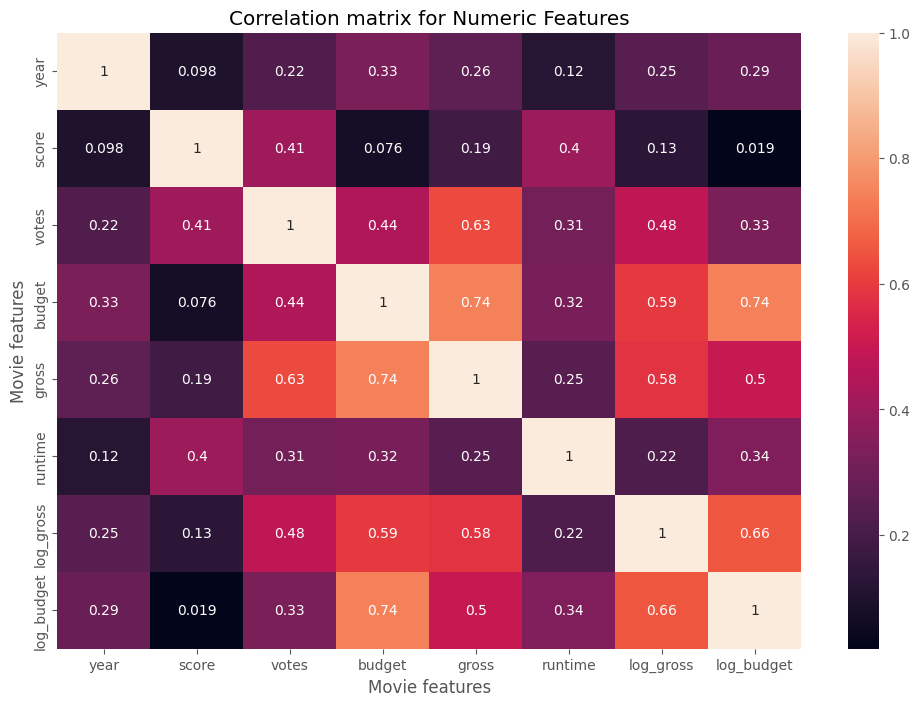

In [ ]:
correlation_matrix = df.corr(numeric_only=True)

sns.heatmap(correlation_matrix, annot=True)

plt.title("Correlation matrix for Numeric Features")
plt.xlabel("Movie features")
plt.ylabel("Movie features")
plt.show()

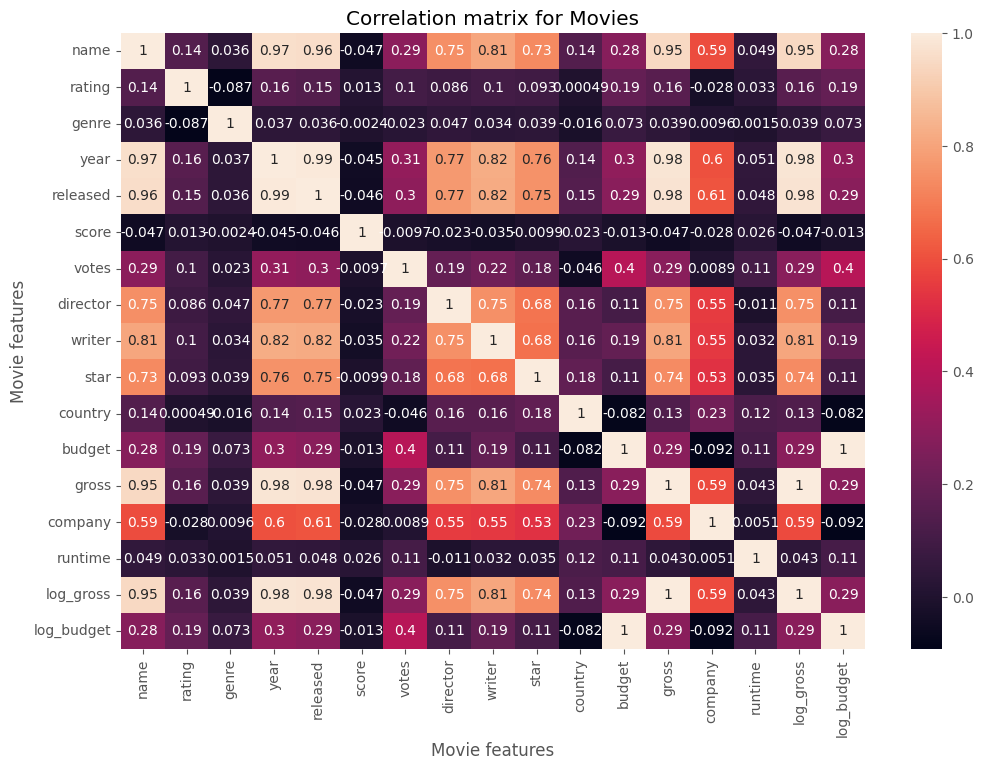

In [ ]:
correlation_matrix = df.apply(lambda x: x.factorize()[0]).corr(method='pearson')

sns.heatmap(correlation_matrix, annot = True)

plt.title("Correlation matrix for Movies")
plt.xlabel("Movie features")
plt.ylabel("Movie features")
plt.show()

In [ ]:
correlation_mat = df.apply(lambda x: x.factorize()[0]).corr()

corr_pairs = correlation_mat.unstack()

print(corr_pairs)

name        name          1.000000
            rating        0.143938
            genre         0.036367
            year          0.965761
            released      0.959015
                            ...   
log_budget  gross         0.285832
            company      -0.092249
            runtime       0.112097
            log_gross     0.285832
            log_budget    1.000000
Length: 289, dtype: float64


In [ ]:
sorted_pairs = corr_pairs.sort_values(kind="quicksort")

print(sorted_pairs)

company     budget       -0.092249
budget      company      -0.092249
company     log_budget   -0.092249
log_budget  company      -0.092249
genre       rating       -0.086723
                            ...   
            genre         1.000000
log_gross   log_gross     1.000000
            gross         1.000000
rating      rating        1.000000
name        name          1.000000
Length: 289, dtype: float64


In [ ]:
# рассмотрим значения с высокой корреляцией (> 0,5)

strong_pairs = sorted_pairs[abs(sorted_pairs) > 0.5]

print(strong_pairs)

company    star         0.527116
star       company      0.527116
company    writer       0.546151
writer     company      0.546151
director   company      0.552258
                          ...   
genre      genre        1.000000
log_gross  log_gross    1.000000
           gross        1.000000
rating     rating       1.000000
name       name         1.000000
Length: 91, dtype: float64


In [ ]:
# Рассмотрим 15 крупнейших компаний по объему валовой выручки

CompanyGrossSum = df.groupby('company')[["gross"]].sum()

CompanyGrossSumSorted = CompanyGrossSum.sort_values('gross', ascending = False)[:15]

CompanyGrossSumSorted = CompanyGrossSumSorted['gross'].astype('int64')

CompanyGrossSumSorted

,gross
company,
Warner Bros.,56491421806
Universal Pictures,52514188890
Columbia Pictures,43008941346
Paramount Pictures,40493607415
Twentieth Century Fox,40257053857
Walt Disney Pictures,36327887792
New Line Cinema,19883797684
Marvel Studios,15065592411
DreamWorks Animation,11873612858


In [ ]:
df.groupby(['company', 'year'])[["gross"]].sum()

,,gross
company,year,
"""DIA"" Productions GmbH & Co. KG",2003,44350926.0
"""Weathering With You"" Film Partners",2019,193457467.0
.406 Production,1996,10580.0
1+2 Seisaku Iinkai,2000,1196218.0
10 West Studios,2010,814906.0
...,...,...
i am OTHER,2015,17986781.0
i5 Films,2001,10031529.0
iDeal Partners Film Fund,2013,506303.0


In [ ]:
CompanyGrossSum = df.groupby(['company', 'year'])[["gross"]].sum()

CompanyGrossSumSorted = CompanyGrossSum.sort_values(['gross','company','year'], ascending = False)[:15]

CompanyGrossSumSorted = CompanyGrossSumSorted['gross'].astype('int64')

CompanyGrossSumSorted

company                year
Walt Disney Pictures   2019    5773131804
Marvel Studios         2018    4018631866
Universal Pictures     2015    3834354888
Twentieth Century Fox  2009    3793491246
Walt Disney Pictures   2017    3789382071
Paramount Pictures     2011    3565705182
Warner Bros.           2010    3300479986
                       2011    3223799224
Walt Disney Pictures   2010    3104474158
Paramount Pictures     2014    3071298586
Columbia Pictures      2006    2934631933
                       2019    2932757449
Marvel Studios         2019    2797501328
Warner Bros.           2018    2774168962
Columbia Pictures      2011    2738363306
Name: gross, dtype: int64

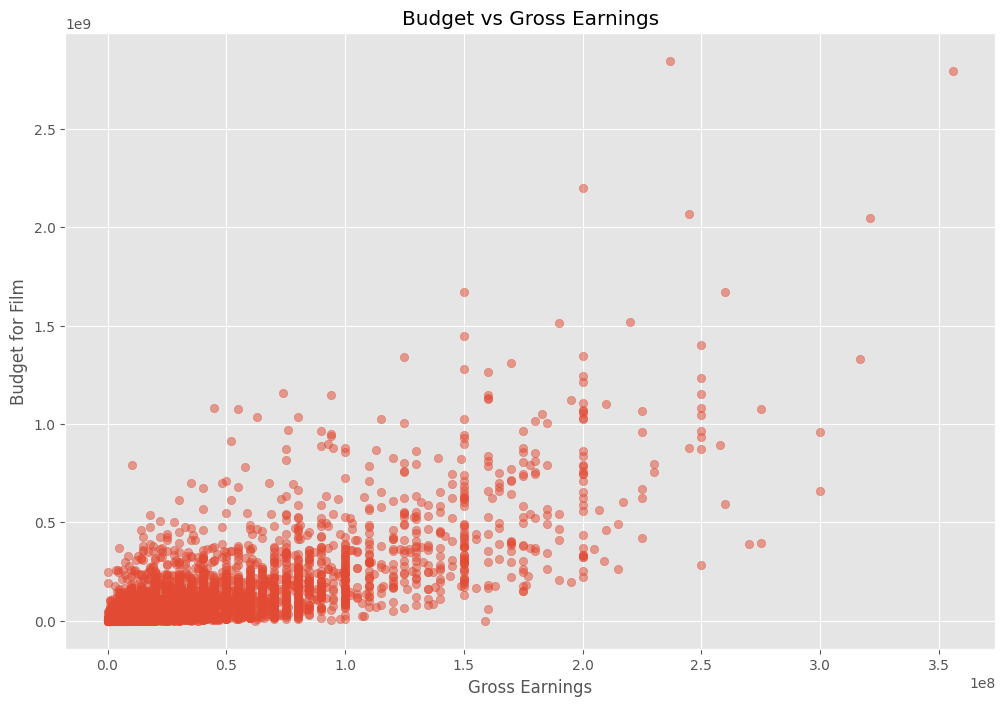

In [ ]:
plt.scatter(x=df['budget'], y=df['gross'], alpha=0.5)
plt.title('Budget vs Gross Earnings')
plt.xlabel('Budget for Film')
plt.ylabel('Gross Earnings')
plt.show()